# 5.0 - Escolha do algoritmo do modelo

O modelo escolhido nos notebooks 3.0 e 4.0 (`PREVISOR_POR_CABECA`):

- **15 a 120 min**: persistencia (o score da camera agora).
- **180 a 360 min**: `base_estado` = tags + calendario + estado da camera (`MODELO_ATUAL`).

Pergunta: com as MESMAS features, algum algoritmo e melhor que o LightGBM (ou que a persistencia)?

| Algoritmo | Como funciona | Contra overfitting |
|---|---|---|
| `lightgbm` | boosting, arvore cresce folha por folha | 200 arvores, profundidade 3 (7 folhas), lr 0,05 |
| `xgboost` | boosting, arvore cresce nivel por nivel | 200 arvores, profundidade 3, lr 0,05 |
| `gradient_boosting` | boosting classico do sklearn (NaN -> mediana do treino) | 200 arvores, profundidade 3, lr 0,05 |
| `random_forest` | 300 arvores independentes, a probabilidade e a media das arvores | profundidade 8, sqrt das colunas por divisao |

Freio igual para todos: cada folha com pelo menos `FOLHA_MINIMA` = 300 linhas (~1 dia de dados de 5 em 5 min).
Assim uma folha nao consegue decorar um episodio de pluma (que dura algumas horas). Com 100 linhas por folha,
o AP no treino era ~0,86 e na validacao ~0,17: o modelo decorava o treino.

Mesmo metodo do 4.0: AP por fold do CV temporal (so treino), mesmas linhas e folds para todos (comparacao pareada),
Reality Check (bootstrap por dias) contra o previsor atual de cada cabeca + Holm. Overfitting: AP no treino x AP na validacao.
O hold out so confere no final.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ml_atmospheric_emission.config import PATH_REPORTS, CABECAS_POSSIVEIS, PREVISOR_POR_CABECA, MODELO_ATUAL, ALGORITMOS, ALGORITMO
from ml_atmospheric_emission.dataset import load_interim
from ml_atmospheric_emission.features import create_training_dataset
from ml_atmospheric_emission.modeling.train import train_algorithms_cv
from ml_atmospheric_emission.modeling.evaluate import split_holdout, average_precision, compare_algorithms, holdout_algorithms
from ml_atmospheric_emission.plots import plot_persistence, plot_algorithms

## Dados: os mesmos passos do `features.main` (pipeline do modelo escolhido)

calendario -> y (score da camera) -> sem os dias suspeitos -> estado da camera -> alvos das cabecas (`y_15` ... `y_360`)

In [3]:
ds = create_training_dataset(load_interim(), CABECAS_POSSIVEIS)
print('Colunas do modelo (base_estado):', MODELO_ATUAL)

#The hold out (last 20% of the period) is separated ONCE
dx_treino, dx_holdout = split_holdout(ds)

Colunas do modelo (base_estado): ['306-AIT-004-2', '306-AIT-004-5', '306FE002-AI001-R', '406-AI-004-2', '406-AI-004-4', '406-AIT-001', 'Hora', 'Minuto', 'Dia_Semana', 'score_atual', 'score_max_30']
Treino ate: 2026-10-02 23:15:00 | linhas treino: 11598 | linhas hold out: 2900


## Como a persistencia e calculada

1. `y` = `nn_score_smog`: o score da rede neural da camera no instante t (0 = sem pluma, 1 = pluma).
2. A previsao da persistencia para QUALQUER cabeca k e o proprio score agora: $\hat p(t+k) = y(t)$. Nao tem treino.
3. O alvo da cabeca k e o score k minutos depois, `y_k` = $y(t+k)$, e a classe real e pluma se $y(t+k) \ge 0{,}5$.
4. O AP ordena as linhas pelo score agora: se os maiores scores agora sao os que tem pluma depois, o AP e alto.

Na tabela: a coluna `previsao_persistencia` e igual em todas as cabecas (e o score agora); o que muda e o alvo.

In [4]:
#Some rows of the day with more plume hours: the forecast is the score now, the target is the score k minutes later
dia = (dx_treino['y'] >= 0.5).groupby(dx_treino['Data'].dt.date).sum().idxmax()
exemplo = dx_treino[dx_treino['Data'].dt.date == dia][['Data', 'y', 'y_15', 'y_60', 'y_180']].iloc[::24].head(10).copy()
exemplo = exemplo.rename(columns={'y': 'previsao_persistencia (score agora)'})
exemplo.round({'previsao_persistencia (score agora)': 3, 'y_15': 3, 'y_60': 3, 'y_180': 3})

,Data,previsao_persistencia (score agora),y_15,y_60,y_180
117,2026-08-21 00:00:00,0.000,0.000,0.000,0.000
141,2026-08-21 02:00:00,0.000,0.000,0.000,0.000
165,2026-08-21 04:00:00,0.000,0.000,0.000,0.000
189,2026-08-21 06:00:00,0.000,0.000,0.000,0.998
213,2026-08-21 08:00:00,0.876,0.928,0.998,0.994
237,2026-08-21 10:05:00,0.992,0.946,0.987,0.900
261,2026-08-21 12:05:00,0.988,0.969,0.900,0.146
285,2026-08-21 14:05:00,0.697,0.504,0.146,0.021
309,2026-08-21 16:05:00,0.020,0.012,0.021,0.004
333,2026-08-21 18:05:00,0.014,0.009,0.004,0.000


 minutos  prevalencia  ap_persistencia
      15        0.065            0.582
      30        0.065            0.446
      60        0.065            0.319
      90        0.064            0.264
     120        0.063            0.192
     180        0.062            0.112
     240        0.061            0.075
     360        0.061            0.063


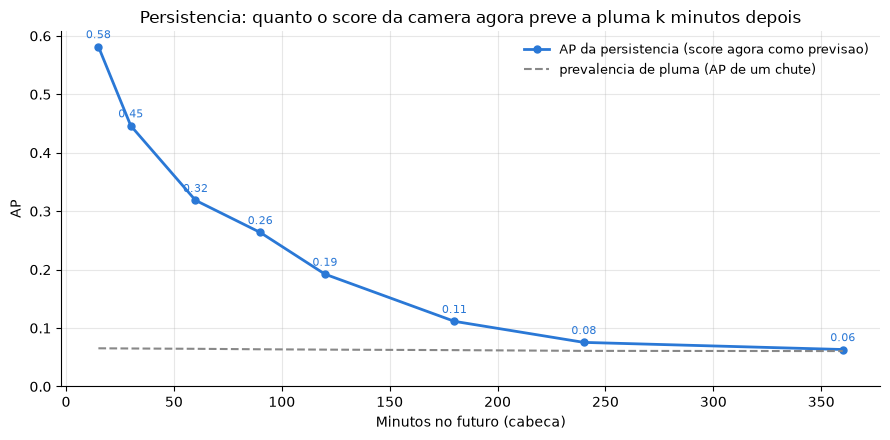

In [5]:
#AP of the persistence in each head (train period): rows ordered by the score now, target = plume k minutes later
#Here the whole train period at once; the decision tables use the mean by fold of the CV (a bit different numbers)
linhas = []
for minutos in CABECAS_POSSIVEIS:
    dx = dx_treino[dx_treino['y_' + str(minutos)].notna()]
    classe = (dx['y_' + str(minutos)] >= 0.5).astype(int)
    linhas.append({'minutos': minutos, 'prevalencia': classe.mean(), 'ap_persistencia': average_precision(classe.values, dx['y'].values)})
tabela_persistencia = pd.DataFrame(linhas)
print(tabela_persistencia.round(3).to_string(index=False))
plot_persistence(tabela_persistencia, PATH_REPORTS / 'figures/persistencia.png')

## Comparacao dos 4 algoritmos (CV temporal, so treino)

Demora alguns minutos (o `gradient_boosting` do sklearn e o mais lento).

In [6]:
tabelas, ap_treino = train_algorithms_cv(dx_treino, MODELO_ATUAL, CABECAS_POSSIVEIS, ALGORITMOS)

15 min: ok
30 min: ok
60 min: ok
90 min: ok
120 min: ok
180 min: ok
240 min: ok
360 min: ok


## Decisao por cabeca

Referencia = previsor atual: `persistencia` (15 a 120 min) ou o `ALGORITMO` atual (180 a 360 min).
O melhor dos outros algoritmos so substitui a referencia se a melhoria for significativa (Reality Check + Holm).

In [7]:
tabela_algoritmos = compare_algorithms(tabelas, PREVISOR_POR_CABECA, ALGORITMO)
tabela_algoritmos.round(3)

15 min | referencia: persistencia | melhor: xgboost | ganho: 0.046 | p: 0.025
30 min | referencia: persistencia | melhor: xgboost | ganho: 0.044 | p: 0.025
60 min | referencia: persistencia | melhor: random_forest | ganho: 0.03 | p: 0.127
90 min | referencia: persistencia | melhor: lightgbm | ganho: 0.071 | p: 0.001
120 min | referencia: persistencia | melhor: random_forest | ganho: 0.075 | p: 0.002
180 min | referencia: lightgbm | melhor: gradient_boosting | ganho: 0.006 | p: 0.766
240 min | referencia: lightgbm | melhor: xgboost | ganho: 0.018 | p: 0.431
360 min | referencia: lightgbm | melhor: gradient_boosting | ganho: -0.013 | p: 1.0


,minutos,previsor_atual,referencia,ap_persistencia,ap_lightgbm,ap_xgboost,ap_gradient_boosting,ap_random_forest,melhor,ganho,ic_inf,ic_sup,p_valor,p_holm,melhoria,nova_escolha
0,15,persistencia,persistencia,0.488,0.519,0.534,0.449,0.448,xgboost,0.046,0.006,0.062,0.025,0.150,False,persistencia
1,30,persistencia,persistencia,0.360,0.385,0.404,0.363,0.377,xgboost,0.044,-0.002,0.072,0.025,0.150,False,persistencia
2,60,persistencia,persistencia,0.246,0.271,0.264,0.269,0.276,random_forest,0.030,-0.023,0.055,0.127,0.506,False,persistencia
3,90,persistencia,persistencia,0.201,0.273,0.245,0.264,0.268,lightgbm,0.071,0.013,0.108,0.001,0.008,True,lightgbm
4,120,persistencia,persistencia,0.147,0.188,0.192,0.185,0.221,random_forest,0.075,0.027,0.094,0.002,0.014,True,random_forest
5,180,base_estado,lightgbm,0.103,0.178,0.154,0.184,0.168,gradient_boosting,0.006,-0.019,0.056,0.766,1.000,False,lightgbm
6,240,base_estado,lightgbm,0.077,0.159,0.177,0.153,0.138,xgboost,0.018,-0.015,0.060,0.431,1.000,False,lightgbm
7,360,base_estado,lightgbm,0.080,0.152,0.139,0.139,0.126,gradient_boosting,-0.013,-0.025,0.005,1.000,1.000,False,lightgbm


In [8]:
#Overfitting: AP in the train rows - AP in the validation (CV). Small difference = the model did not memorize the train
tabela_overfit = ap_treino.copy()
for nome in ALGORITMOS:
    tabela_overfit[nome] = ap_treino[nome].values - tabela_algoritmos['ap_' + nome].values
print('AP no treino (media dos folds):')
print(ap_treino.round(3).to_string(index=False))
print()
print('AP no treino - AP na validacao:')
print(tabela_overfit.round(3).to_string(index=False))

AP no treino (media dos folds):
 minutos  lightgbm  xgboost  gradient_boosting  random_forest
      15     0.841    0.799              0.821          0.698
      30     0.800    0.753              0.773          0.638
      60     0.769    0.724              0.756          0.554
      90     0.758    0.706              0.742          0.501
     120     0.739    0.687              0.727          0.471
     180     0.739    0.668              0.733          0.419
     240     0.754    0.673              0.765          0.411
     360     0.763    0.695              0.759          0.495

AP no treino - AP na validacao:
 minutos  lightgbm  xgboost  gradient_boosting  random_forest
      15     0.322    0.265              0.371          0.250
      30     0.415    0.349              0.410          0.261
      60     0.498    0.459              0.488          0.278
      90     0.485    0.461              0.479          0.233
     120     0.551    0.495              0.542          0.249
     

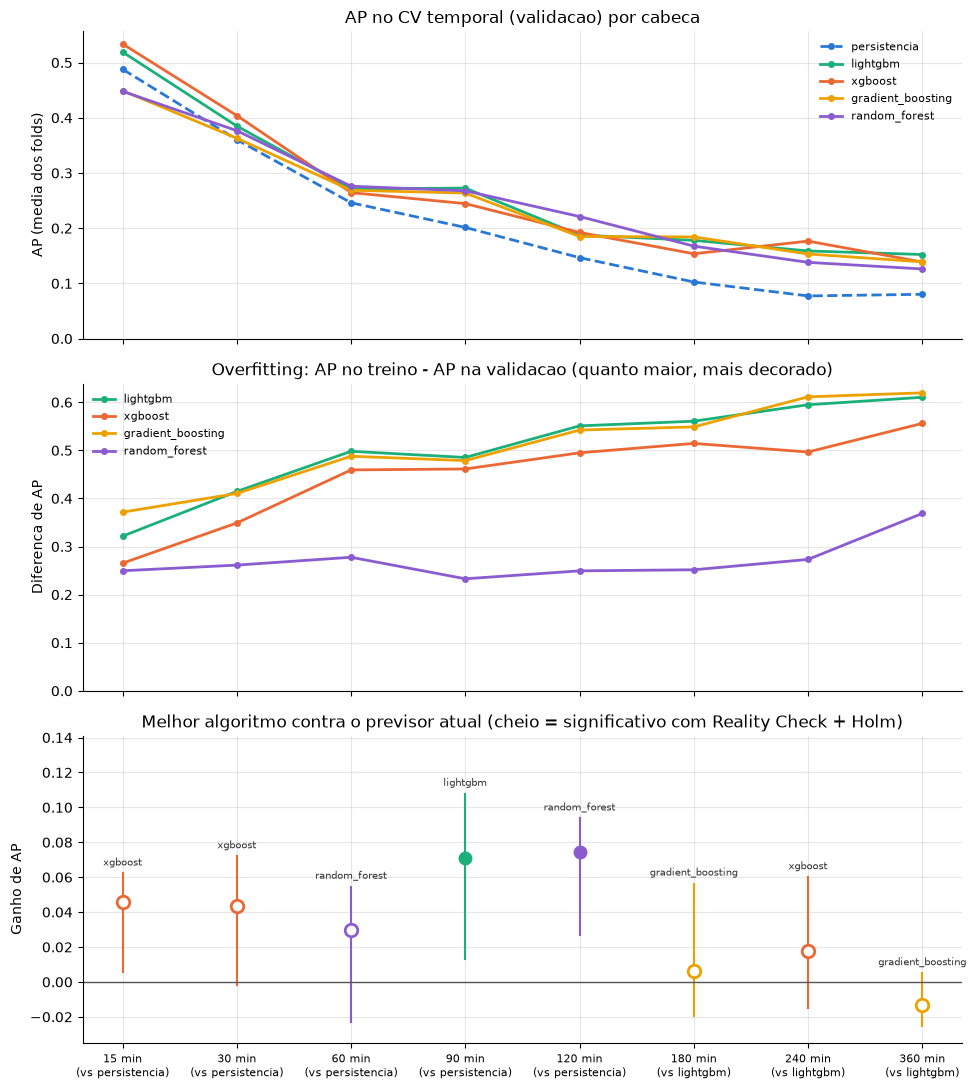

In [9]:
plot_algorithms(tabela_algoritmos, ap_treino, PATH_REPORTS / 'figures/escolha_algoritmo.png')

## Hold out (usado uma vez so): a ordem do CV se mantem em dias novos?

In [10]:
tabela_teste = holdout_algorithms(dx_treino, dx_holdout, CABECAS_POSSIVEIS, MODELO_ATUAL, ALGORITMOS)
tabela_teste.round(3)

,minutos,prevalencia_teste,ap_teste_persistencia,ap_teste_lightgbm,ap_teste_xgboost,ap_teste_gradient_boosting,ap_teste_random_forest
0,15,0.123,0.721,0.798,0.800,0.798,0.784
1,30,0.124,0.632,0.730,0.752,0.733,0.694
2,60,0.124,0.471,0.609,0.621,0.591,0.525
3,90,0.125,0.368,0.513,0.507,0.495,0.460
4,120,0.125,0.323,0.469,0.479,0.475,0.447
5,180,0.126,0.266,0.454,0.423,0.451,0.513
6,240,0.126,0.240,0.411,0.428,0.425,0.525
7,360,0.128,0.164,0.506,0.511,0.507,0.475


## Resultado

In [11]:
tabela_algoritmos.to_csv(PATH_REPORTS / 'escolha_algoritmo.csv', index=False)
tabela_overfit.to_csv(PATH_REPORTS / 'escolha_algoritmo_overfit.csv', index=False)
tabela_teste.to_csv(PATH_REPORTS / 'escolha_algoritmo_teste.csv', index=False)

if tabela_algoritmos['melhoria'].any():
    print('HOUVE MELHORIA:')
    for i in range(len(tabela_algoritmos)):
        if tabela_algoritmos['melhoria'].iloc[i]:
            print('   ', int(tabela_algoritmos['minutos'].iloc[i]), 'min:', tabela_algoritmos['nova_escolha'].iloc[i],
                  'vence', tabela_algoritmos['referencia'].iloc[i])
    print('Confira o hold out acima antes de mudar ALGORITMO / PREVISOR_POR_CABECA no config.py')
else:
    print('NAO HOUVE MELHORIA: nenhum algoritmo venceu o previsor atual de forma significativa.')
    print('ALGORITMO continua', repr(ALGORITMO), '| PREVISOR_POR_CABECA continua igual:', PREVISOR_POR_CABECA)
print()
print('Para treinar os modelos finais e prever (terminal, na pasta do projeto, com o .venv ativo):')
print('    make pipeline')

HOUVE MELHORIA:
    90 min: lightgbm vence persistencia
    120 min: random_forest vence persistencia
Confira o hold out acima antes de mudar ALGORITMO / PREVISOR_POR_CABECA no config.py

Para treinar os modelos finais e prever (terminal, na pasta do projeto, com o .venv ativo):
    make pipeline
